In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

In [2]:
np.random.seed(42)
X, Y = make_circles(n_samples=500, factor=0.1, noise=0.35,  random_state=42)

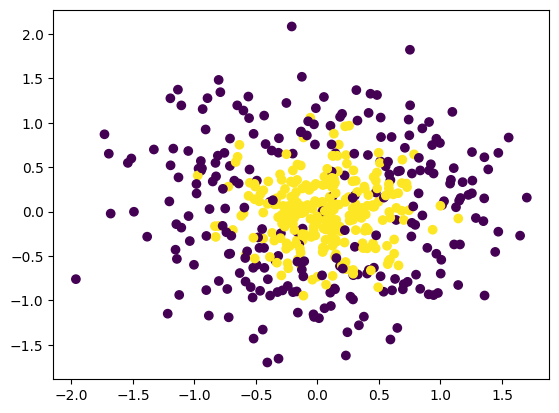

In [3]:
plt.scatter(X[:,0], X[:,1], c=Y)

In [4]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

abc = AdaBoostClassifier()

In [5]:
np.mean(cross_val_score(abc, X, Y, scoring='accuracy', cv=10))

np.float64(0.812)

In [6]:
abc.fit(X, Y)

AdaBoostClassifier()

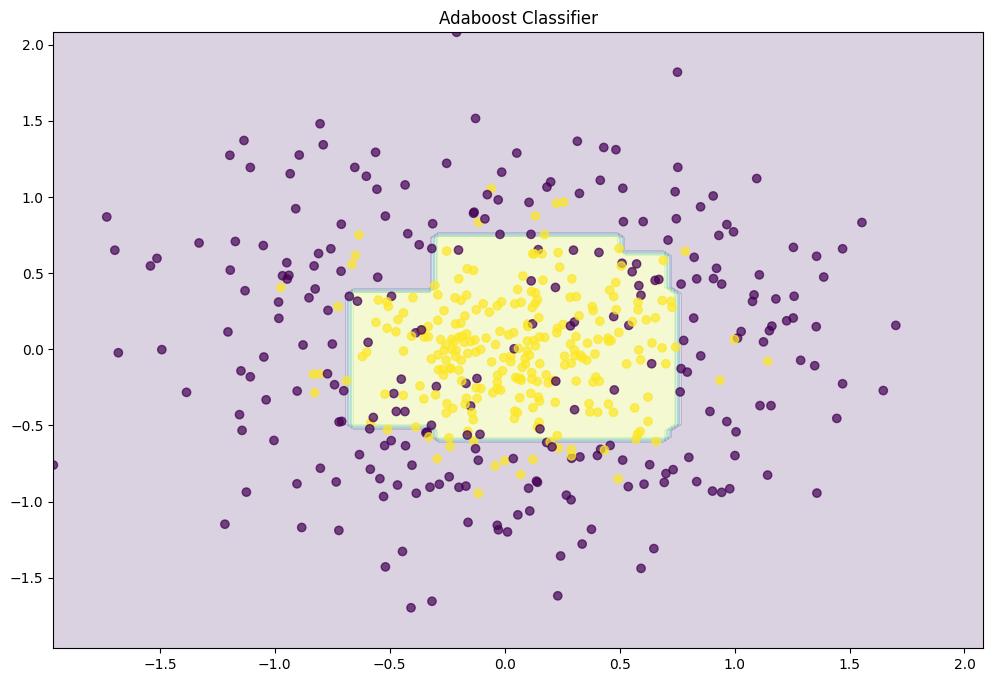

In [7]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    x1, x2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[x1.ravel(), x2.ravel()])
    y_hat = y_hat.reshape(x1.shape)
    plt.contourf(x1, x2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=Y, cmap='viridis', alpha=0.7)
    plt.title("Adaboost Classifier")
    plt.show()

plot_decision_boundary(abc)

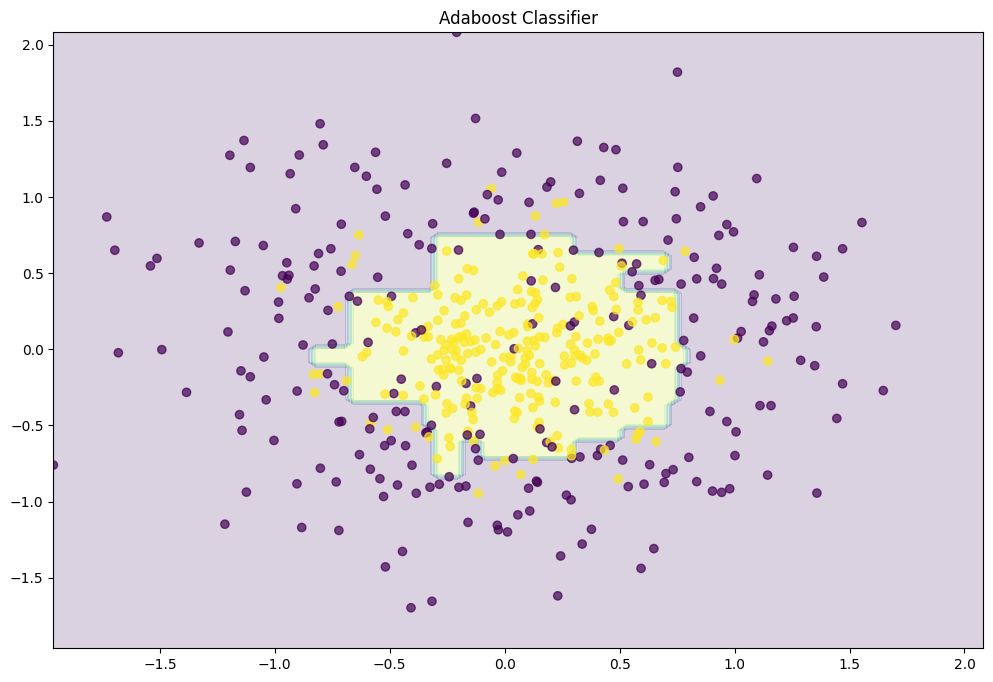

In [15]:
abc = AdaBoostClassifier(n_estimators=1000)  # model is overfitting
abc.fit(X, Y)
plot_decision_boundary(abc)

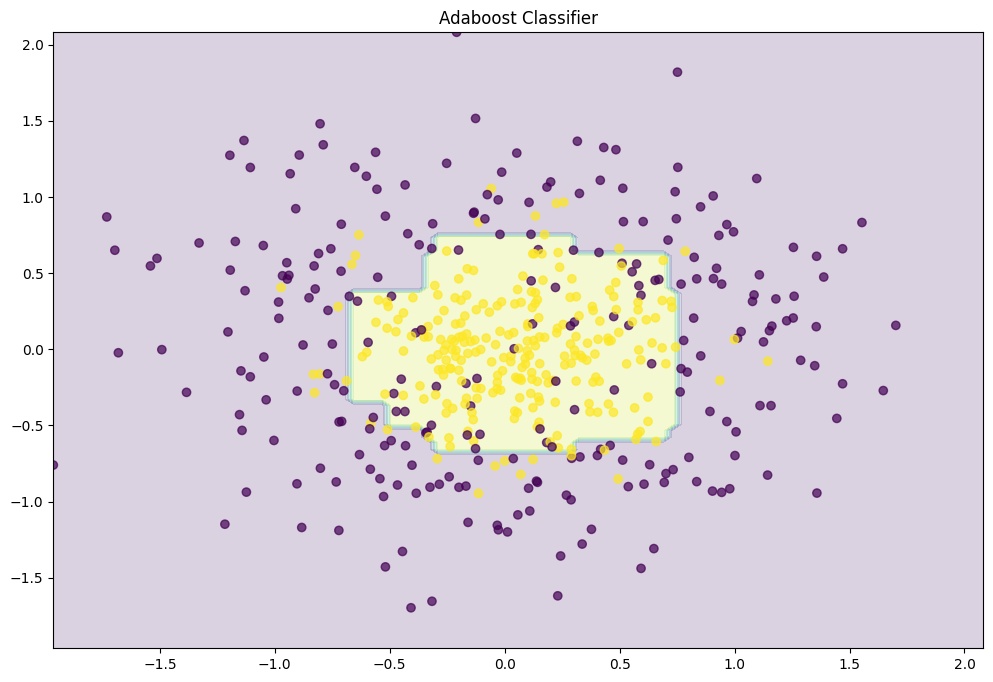

In [19]:
abc = AdaBoostClassifier(n_estimators=2000, learning_rate=0.2)  
abc.fit(X, Y)
plot_decision_boundary(abc)

In [12]:
from sklearn.model_selection import GridSearchCV

grid = dict()
grid['n_estimators'] = [10, 50, 100, 500, 1000]
grid['learning_rate'] = [0.0001, 0.001, 0.01, 0.1, 0.5, 1.0]
grid['algorithm'] = ['SAMME', 'SAMME.R']

grid_search = GridSearchCV (estimator = AdaBoostClassifier(), param_grid = grid, 
                             n_jobs=-1, cv=10, scoring='accuracy')
grid_result = grid_search.fit(X, Y)

# summarize the best score and configuration :
print("Best: %f using %s" %(grid_result.best_score_, grid_result.best_params_))


C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
300 fits failed out of a total of 600.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
300 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:

Best: 0.832000 using {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 500}
